Epoch 10 / 100, Cost: 0.161465
Epoch 20 / 100, Cost: 0.160871
Epoch 30 / 100, Cost: 0.161606
Epoch 40 / 100, Cost: 0.161327
Epoch 50 / 100, Cost: 0.161553
Epoch 60 / 100, Cost: 0.161899
Epoch 70 / 100, Cost: 0.162213
Epoch 80 / 100, Cost: 0.161731
Epoch 90 / 100, Cost: 0.161039
Epoch 100 / 100, Cost: 0.161719

Training accuracy 93.75%
Test accuracy: 95.00%
Final weights: [ 0.83325935 -0.15637476]
Final bias : 0.0172
Final cost: 0.161719


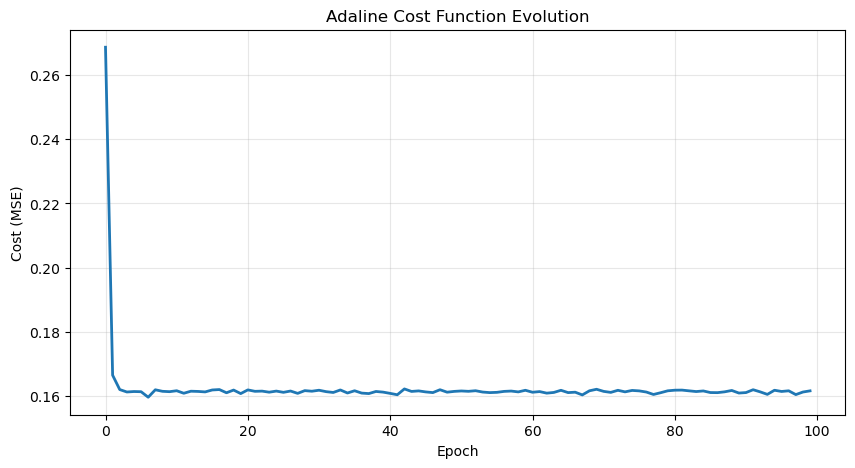


ADALINE ON LOGIC GATES

Training ADALINE on AND gate
Weights : [0.99711529 0.997156  ]
Bias: -1.4604
Final cost: 0.153697

Truth Table:
 A B | Target | Linear Out | Prediction | Status 
-----+--------+------------+------------+--------
0 0 | 0 |  -1.4604 | 0 | OK
0 1 | 0 |  -0.4632 | 0 | OK
1 0 | 0 |  -0.4632 | 0 | OK
1 1 | 1 |  0.5339 | 1 | OK

Accuracy : 100.00%


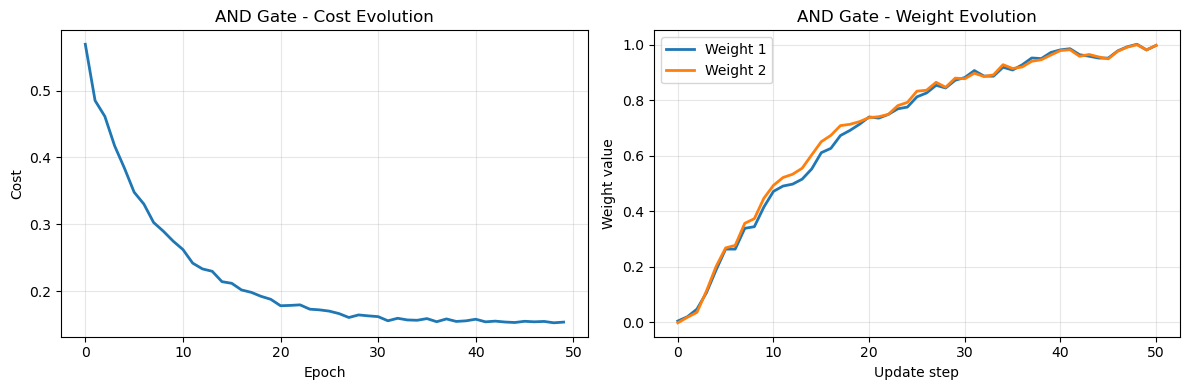


Training ADALINE on OR gate
Weights : [0.94190014 0.94130868]
Bias: -0.4622
Final cost: 0.152469

Truth Table:
 A B | Target | Linear Out | Prediction | Status 
-----+--------+------------+------------+--------
0 0 | 0 |  -0.4622 | 0 | OK
0 1 | 1 |  0.4791 | 1 | OK
1 0 | 1 |  0.4797 | 1 | OK
1 1 | 1 |  1.4210 | 1 | OK

Accuracy : 100.00%


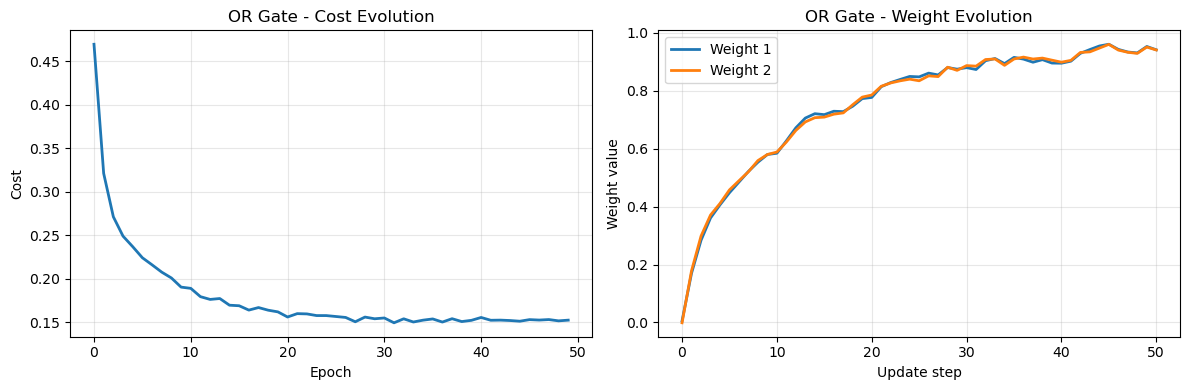


Training ADALINE on NAND gate
Weights : [-0.94180706 -0.94126732]
Bias: 0.4621
Final cost: 0.152469

Truth Table:
 A B | Target | Linear Out | Prediction | Status 
-----+--------+------------+------------+--------
0 0 | 1 |  0.4621 | 1 | OK
0 1 | 0 |  -0.4791 | 0 | OK
1 0 | 0 |  -0.4797 | 0 | OK
1 1 | 0 |  -1.4209 | 0 | OK

Accuracy : 100.00%


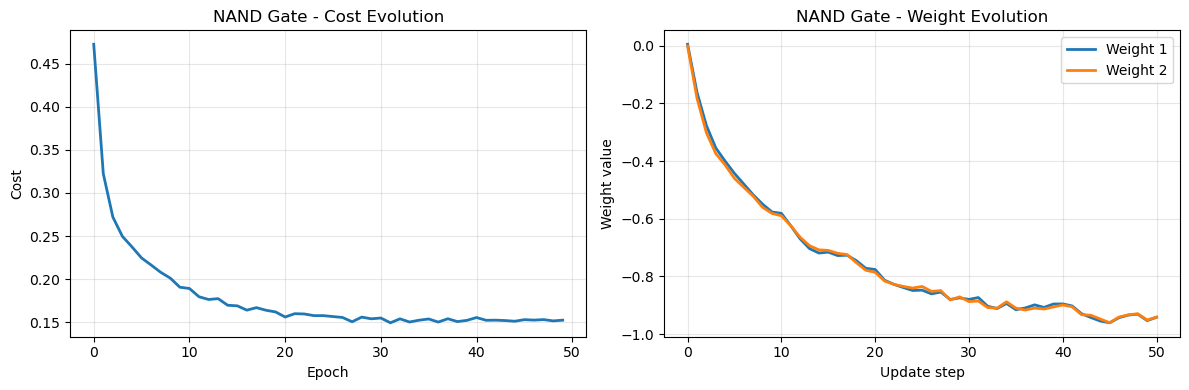


Training ADALINE on NOR gate
Weights : [-0.94180706 -0.94126732]
Bias: 0.4621
Final cost: 0.152469

Truth Table:
 A B | Target | Linear Out | Prediction | Status 
-----+--------+------------+------------+--------
0 0 | 1 |  0.4621 | 1 | OK
0 1 | 0 |  -0.4791 | 0 | OK
1 0 | 0 |  -0.4797 | 0 | OK
1 1 | 0 |  -1.4209 | 0 | OK

Accuracy : 100.00%


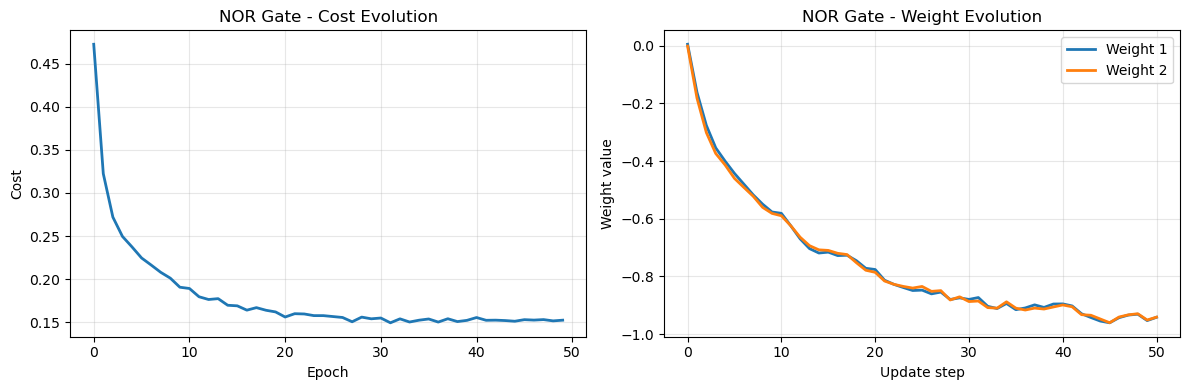


Training ADALINE on XOR gate
Weights : [-0.10636459 -0.0770142 ]
Bias: -0.0061
Final cost: 0.619100

Truth Table:
 A B | Target | Linear Out | Prediction | Status 
-----+--------+------------+------------+--------
0 0 | 0 |  -0.0061 | 0 | OK
0 1 | 1 |  -0.0831 | 0 | FAIL
1 0 | 1 |  -0.1125 | 0 | FAIL
1 1 | 0 |  -0.1895 | 0 | OK

Accuracy : 50.00%


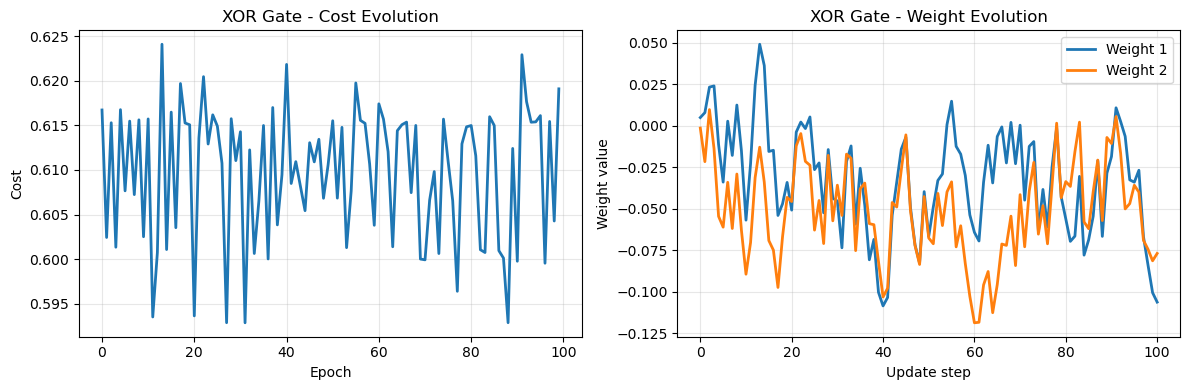

NameError: name 'Perceptron' is not defined

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

class Adaline:
    # Adaptive linear neuron classifier
    def __init__(self, learning_rate=0.01, n_epochs=50, batch_size = None, random_state=None):
        self.lr = learning_rate
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.weights = None
        self.bias = None
        self.cost_history = [] # Track MSE per epoch
        self.weights_history = [] 
    def net_input(self,X):
        return np.dot(X,self.weights) + self.bias
    def activation(self, X):
        return self.net_input(X)
    def predict(self, X):
        return np.where(self.net_input(X) >= 0.0, 1, -1)
    def _initialize_weights(self,n_features):
        if self.random_state:
            np.random.seed(self.random_state)
        self.weights = np.random.randn(n_features) *0.01
        self.bias = 0.0
    def fit(self, X, y, verbose=True):
        n_samples, n_features = X.shape
        self._initialize_weights(n_features)
        self.cost_history = []
        self.weights_history = [self.weights.copy()]
        # Determine batch processing mode
        if self.batch_size == 'batch':
            # batch gradient descent (use all samples)
            batch_indices = [np.arange(n_samples)]
        elif self.batch_size is None or self.batch_size >= n_samples:
            #Stochastic gradient descent (one sample at a time)
            batch_indices = [[i] for i in range (n_samples)]
        else:
            # Mini-batch gradient descent
            n_batches = max(1,n_samples // self.batch_size)
            batch_indices =[]
            for i in range(n_batches):
                start = i *self.batch_size
                end = min((i+1) * self.batch_size , n_samples)
                batch_indices.append(np.arange(start,end))
        for epoch in range(self.n_epochs):
            #Shuffle data for stochastic/mini_batch
            if self.batch_size != 'batch':
                indices = np.random.permutation(n_samples)
                X_shuffled = X[indices]
                y_shuffled = y[indices]
            else:
                X_shuffled = X
                y_shuffled = y
            epoch_cost = 0
            for batch_idx in batch_indices:
                X_batch = X_shuffled[batch_idx]
                y_batch = y_shuffled[batch_idx]

                # compute linear output for batch
                output = self.activation(X_batch)
                # compute errors 
                errors = y_batch - output 
                # Update weights (gradient descent)
                self.weights += self.lr * np.dot(X_batch.T, errors) / len(batch_idx)
                self.bias += self.lr * np.sum(errors) / len(batch_idx)
                # Accumulate cost
                epoch_cost += np.sum(errors**2)
            # Average cost for this epoch
            epoch_cost /= (2 * n_samples)
            self.cost_history.append(epoch_cost)
            self.weights_history.append(self.weights.copy())
            if verbose and (epoch+ 1) % 10 == 0:
                print(f"Epoch {epoch +1 } / {self.n_epochs}, Cost: {epoch_cost:.6f}")
        return self
    def score(self, X, y):
        # Compute accuracy for classification
        predictions = self.predict(X)
        return np.mean(predictions == y)
# Test on simple data 
X, y = make_classification(
    n_samples = 200, n_features = 2, n_redundant =0,
    n_clusters_per_class = 1, class_sep = 1.5, random_state= 42
)
y=np.where(y == 0, -1, 1)
# Train-test split
X_train, X_test, y_train,y_test = train_test_split(X,y, test_size = 0.2, random_state=42)
#Standardize(crucial for ADALINE)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
#Train ADALINE
adaline = Adaline(learning_rate = 0.01, n_epochs = 100, random_state = 42)
adaline.fit(X_train_scaled, y_train, verbose=True)
#Evaluate
train_acc = adaline.score(X_train_scaled, y_train)
test_acc = adaline.score(X_test_scaled , y_test)
print(f"\nTraining accuracy {train_acc :.2%}")
print(f"Test accuracy: {test_acc:.2%}")
print(f"Final weights: {adaline.weights}")
print(f"Final bias : {adaline.bias:.4f}")
print(f"Final cost: {adaline.cost_history[-1]:.6f}")
# Plot cost history
plt.figure(figsize = (10, 5))
plt.plot(adaline.cost_history, linewidth =2)
plt.xlabel("Epoch")
plt.ylabel("Cost (MSE)")
plt.title("Adaline Cost Function Evolution")
plt.grid(True, alpha=0.3)
plt.show()
# Data for logic gates (in -1/1 format)
X_logic = np.array([[0,0], [0,1], [1,0], [1,1]])
# Truth tables in -1/1 format
y_and = np.array([-1, -1, -1, 1]) #AND
y_or = np.array([-1, 1, 1, 1]) #OR
y_nand = np.array([1, -1, -1, -1]) #NAND
y_nor = np.array([1, -1, -1, -1]) # NOR
y_xor = np.array([-1, 1, 1, -1]) #XOR
def train_and_evaluate_adaline(X, y,gate_name, learning_rate=0.1, epochs=50):
    print(f"\n{'='*50}")
    print(f"Training ADALINE on {gate_name} gate")
    print('='*50)
    #For logic gates , we don't need standardization
    adaline = Adaline(learning_rate = learning_rate, n_epochs = epochs, random_state=42)
    adaline.fit(X, y, verbose = False)
    #Get linear ouptputs (before sign)
    linear_outputs = adaline.activation(X)
    predictions = adaline.predict(X)
    print(f"Weights : {adaline.weights}")
    print(f"Bias: {adaline.bias:.4f}")
    print(f"Final cost: {adaline.cost_history[-1]:.6f}")
    print("\nTruth Table:")
    print(" A B | Target | Linear Out | Prediction | Status ")
    print("-----+--------+------------+------------+--------")
    for i, (x, target,linear, pred) in enumerate(zip(X, y, linear_outputs, predictions)):
        status = "OK" if target == pred else "FAIL"
        target_val = 1 if target == 1 else 0
        pred_val = 1 if pred == 1 else 0
        print(f"{int(x[0])} {int(x[1])} | {target_val} |  {linear:6.4f} | {pred_val} | {status}")
    accuracy = np.mean(predictions == y)
    print(f"\nAccuracy : {accuracy:.2%}")
    #Plot cost evolution
    plt.figure(figsize=(12,4))
    plt.subplot(1, 2, 1)
    plt.plot(adaline.cost_history, linewidth=2)
    plt.xlabel("Epoch")
    plt.ylabel("Cost")
    plt.title(f"{gate_name} Gate - Cost Evolution")
    plt.grid(True, alpha=0.3)
    # Plot weight evolution 
    plt.subplot(1, 2, 2)
    weights_history = np.array(adaline.weights_history)
    plt.plot(weights_history[:, 0], label="Weight 1", linewidth =2)
    plt.plot(weights_history[:, 1], label ="Weight 2", linewidth=2)
    plt.xlabel("Update step")
    plt.ylabel("Weight value")
    plt.title(f"{gate_name} Gate - Weight Evolution")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    return adaline
# Train on different gates
print("\n" + "=" * 60)
print("ADALINE ON LOGIC GATES")
print("="*60)
a_and = train_and_evaluate_adaline(X_logic, y_and, "AND", learning_rate= 0.1, epochs = 50)
a_or = train_and_evaluate_adaline(X_logic, y_or, "OR", learning_rate=0.1, epochs=50)
a_nand = train_and_evaluate_adaline(X_logic, y_nand, "NAND", learning_rate= 0.1, epochs=50)
a_nor = train_and_evaluate_adaline(X_logic, y_nor, "NOR", learning_rate = 0.1, epochs = 50)
a_xor = train_and_evaluate_adaline(X_logic, y_xor, "XOR", learning_rate = 0.1, epochs =100)
# Train both models on XOR
p_xor = Perceptron(learning_rate=0.1, n_epochs =100, random_state = 42)
p_xor.fit(X_logic, y_xor, verbose = False)
a_xor = Adaline(learning_rate=0.1, n_epochs =100, random_state = 42)
a_xor.fit(X_logic, y_xor, verbose = False)
# Compare 
plt.figure(figsize=(15,5))
plt.subplot(1, 3, 1)
plt.scatter(X_logic[:,0], X_logic[:,1], c+y_xor, cmap='bwr', s=200, edgecolors ='black')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title("XOR Problem")
plt.grid(True , alpha = 0.3)
plt.subplot(1,3,2)

plt.plot(p_xor.errors_history, linewidth =2, label='Perceptron errors', color = 'blue')
plt.xlabel("Epoch")
plt.ylabel('Number of errors')
plt.title('Perceptron on XOR')
plt.grid( True , alpha =0.3)
plt.ylim( -0.5 , 4.5)
plt.subplot(1 , 3 , 3)
plt.plot( a_xor . cost_history , linewidth =2 , label = 'ADALINE cost' ,
color = 'red')
plt.xlabel('Epoch')
plt.ylabel( 'Cost( MSE )')
plt.title('ADALINE on XOR')
plt.grid( True , alpha =0.3)
plt.tight_layout()
plt.show()
print( " \ n " + " = " *60)
print( " PERCEPTRON VS ADALINE ON XOR " )
print( " = " *60)
print( f" Perceptron - Final errors : { p_xor.errors_history [ -1]}/4 " )
print( f" ADALINE - Final cost : { a_xor.cost_history [ -1]:.6 f } " )
print (f" ADALINE - Final linear outputs : " )
linear_out = a_xor.activation( X_logic )
for ( x1 , x2 ) , out in zip( X_logic , linear_out ):
    print ( f" ({ x1 } ,{ x2 }) -> { out :.4 f } -> {1 if out >=0 else 0} " )
print("\nCONCLUSION : ADALINE finds a linear approximation even when")
print( " perfect classification is impossible . The cost decreases smoothly . " )

def compare_adaline_learning_rates(X , y , learning_rates =[0.0001 ,
0.001 , 0.01 , 0.1 , 1.0] , epochs =100) :
    """
    Compare ADALINE performance with different learning rates
    """
    plt.figure ( figsize =(15 , 12) )
    for i , lr in enumerate( learning_rates ) :
        # Train ADALINE
        a = Adaline( learning_rate = lr , n_epochs = epochs ,
        random_state =42)
        a.fit(X , y , verbose = False )
        # Plot cost evolution
        plt.subplot(3 , 2 , i +1)
        plt.plot( a.cost_history , linewidth =2)
        plt.xlabal( 'Epoch')
        plt.ylabel( 'Cost')
        plt.title( f'Learning Rate = { lr } ')
        plt.grid( True , alpha =0.3)
        plt.ylim(0 , min(5 , max(a.cost_history ) *1.1) )
        # Store results
        results[ lr ] = {
        'final_cost': a.cost_history [ -1] ,
        'min_cost ': min(a.cost_history ) ,
        ' final_weights ': a.weights.copy() ,
         'bias ': a.bias
        }
    plt.tight_layout()
    plt.show()
    # Print comparison
    print( " \ n " + " = " *70)
    print( " LEARNING RATE COMPARISON " )
    print( " = " *70)
    print( f" { 'LR ': <10} { 'Final Cost ': <12} { 'Min Cost': <12} { 'Weights ': <25} { ' Bias ': <10} " )
    print( " -" *70)
    for lr, res in results.items():
        weights_str =f"[{res['final_weights'][0]:.3f},{res['final_weights'][1]:.3f}]"
        print(f"{lr:<10.4f} {res['final_cost']:<12.6f} {res['min_cost']:<12.6f}"
              f"{weights_str:<25} {res['bias']:<10.3f}")
    return results     
#Test on AND gate
print( " \ n " + " = " *70)
print( " TESTING DIFFERENT LEARNING RATES ON AND GATE " )
print( " = " *70)
results_and_lr = compare_adaline_learning_rates( X_logic , y_and ,
learning_rates
=[0.001 , 0.01 ,
0.1 , 0.5 , 1.0] ,
epochs =50)
# Test on more complex data
print( " \ n " + " = " *70)
print ( " TESTING DIFFERENT LEARNING RATES ON COMPLEX DATA " )
print ( " = " *70)
results_comp_lr =compare_adaline_learning_rates( X_train_scaled ,
y_train ,
learning_rates
=[0.0001 ,
0.001 , 0.01 ,
0.1 , 1.0] ,
epochs =100)
# Create data with different scales
np.random.seed(42)
n_samples = 200
# Feature 1: large scale (0 -1000) , Feature 2: small scale (0 -0.1)
X_unscaled = np.column_stack([
np.random.rand( n_samples ) * 1000 , # Large scale
np.random.rand( n_samples ) * 0.1
# Small scale
])
# Create a linear decision boundary
y_unscaled = np.where (0.01 * X_unscaled [: , 0] + 100 * X_unscaled
[: , 1] > 5 , 1 , -1)
# Split
X_train_u , X_test_u , y_train_u , y_test_u = train_test_split(
X_unscaled , y_unscaled , test_size =0.3 , random_state =42
)
# Standardize
scaler = StandardScaler ()
X_train_scaled = scaler.fit_transform( X_train_u )
X_test_scaled = scaler.transform( X_test_u )
# Train ADALINE on unscaled data ( need tiny learning rate )
print ( " \ n " + " = " *60)
print ( " TRAINING ON UNSCALED DATA " )
print ( " = " *60)
a_unscaled = Adaline( learning_rate =0.000001 , n_epochs =200 ,
random_state =42)
a_unscaled.fit( X_train_u , y_train_u , verbose = False )
test_acc_unscaled = a_unscaled.score( X_test_u , y_test_u )
print(f" Test accuracy ( unscaled ) : { test_acc_unscaled:.2%} " )
print(f" Final cost ( unscaled ) : { a_unscaled.cost_history[ -1]:.6f } ")
# Train ADALINE on scaled data ( can use normal learning rate )
print("\n" + "="*60)
print("Training on Scaled Data")
print("="*60)
a_scaled = Adaline(learning_rate=0.01, n_epochs = 200, random_state=42)
a_scaled.fit(X_train_scaled, y_train_u, verbose =False)
test_acc_scaled = a_scaled.score(X_test_scaled, y_test_u)
print(f"Test accuracy (scaled): {test_acc_scaled:.2%}")
print(f"Final cost (scaled) : {a_scaled.cost_history[-1]:.6f}")

#Compare convergence
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(a_unscaled.cost_history, linewidth=2, label ='Unscaled')
plt.xlabel('Epoch')
plt.ylabel('Cost')
plt.title('Without Standardization (slow convergence)')
plt.grid(True, alpha=0.3)

plt.subplot(1,2,2)
plt.plot(a_scaled.cost_history, linewidth=2, label='Scaled', color='green')
plt.xlabel('Epoch')
plt.ylabel('Cost')
plt.title('With Standardization (fast convergence)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("\n" + "="*60)
print("Conclusion")
print("="*60)
print("Standardization is crucial or ADALINE becayse:")
print("1. Features with different scales cause uneven updates")
print("2. the cost function becomes elongated (hard to optimize)")
print("3. You need very small learning rates for unscaled data")
print("4. Standardization leads to faster, more stable convergence")

### Batch vs Stochastic vs Mini-Batch Gradient Descent


Gradient Descent Variants comparison
Batch GD - Final cost: 0.151386
SGD - Final cost: 0.192013
Mini-Batch (32) - Final cost: 0.151808


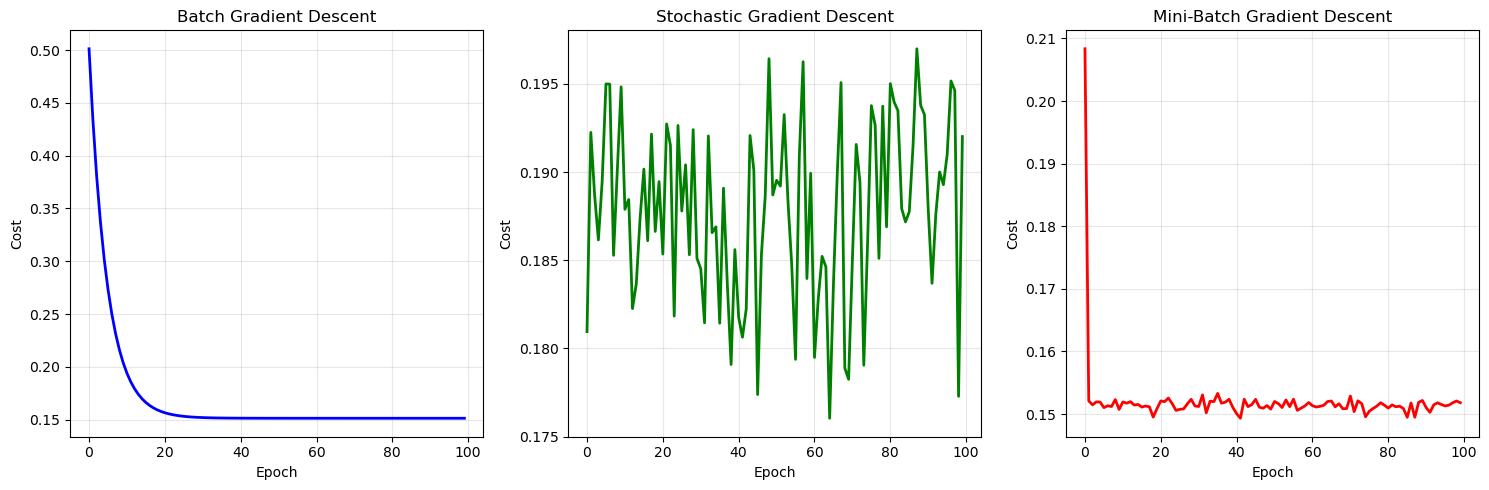


Comparison Table
Method          Pros                                     Cons                          
-------------------------------------------------------------------------------------
Batch GD        Stable convergence, accurate gradient    Slow for large datasets       
SGD             Fast, can escape local minima            Noisy updates, oscillates     
Mini-Batch      Best of both worlds                      Need to tune batch size       


In [34]:
class AdalineSGD(Adaline):
    #ADALINE with Stochastic Gradient Descent (online learning)
    def __init__(self,learning_rate = 0.01, n_epochs =50, random_state=None):
        super().__init__(learning_rate, n_epochs, batch_size = 1,random_state=random_state)
class AdalineMiniBatch(Adaline):
    #ADALINE with Mini-Batch Gradient Descent
    def __init__(self, learning_rate=0.01, n_epochs=50, batch_size=32,random_state= None):
        super().__init__(learning_rate, n_epochs, batch_size=batch_size, random_state=random_state)
class AdalineBatch(Adaline):
    #ADALINE with Batch Gradient Descent
    def __init__(self,learning_rate=0.01, n_epochs=50,random_state= None):
        super().__init__(learning_rate, n_epochs, batch_size='batch',random_state=random_state)

#Compare all three variants
X_comp, y_comp = make_classification(n_samples = 1000, n_features=2, n_redundant=0,n_clusters_per_class=1, class_sep=1.2, random_state=42)
y_comp = np.where(y_comp== 0, -1,1)
scaler= StandardScaler()
X_comp_scaled = scaler.fit_transform(X_comp)
#Train all vairants
print("\n" + "="*70)
print("Gradient Descent Variants comparison")
print("="*70)
a_batch = AdalineBatch(learning_rate=0.1, n_epochs = 100, random_state=42)
a_batch.fit(X_comp_scaled, y_comp, verbose=False)
print(f"Batch GD - Final cost: {a_batch.cost_history[-1]:.6f}")

a_sgd = AdalineSGD(learning_rate = 0.1, n_epochs=100, random_state=42)
a_sgd.fit(X_comp_scaled, y_comp,verbose=False)
print(f"SGD - Final cost: {a_sgd.cost_history[-1]:.6f}")

a_mini = AdalineMiniBatch(learning_rate = 0.1, n_epochs = 100, batch_size = 32, random_state=42)
a_mini.fit(X_comp_scaled, y_comp, verbose = False)
print(f"Mini-Batch (32) - Final cost: {a_mini.cost_history[-1]:.6f}")
# plot comparison
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.plot(a_batch.cost_history, linewidth=2, label='Batch GD',color ='blue')
plt.xlabel('Epoch')
plt.ylabel('Cost')
plt.title('Batch Gradient Descent')
plt.grid(True, alpha=0.3)
plt.subplot(1,3,2)
plt.plot(a_sgd.cost_history, linewidth = 2, label='SGD', color='green')
plt.xlabel('Epoch')
plt.ylabel('Cost')
plt.title('Stochastic Gradient Descent')
plt.grid(True, alpha=0.3)

plt.subplot(1,3,3)
plt.plot(a_mini.cost_history, linewidth=2, label='Mini-Batch',color='red')
plt.xlabel('Epoch')
plt.ylabel('Cost')
plt.title('Mini-Batch Gradient Descent')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("Comparison Table")
print("="*70)
print(f"{'Method':<15} {'Pros':<40} {'Cons':<30}")
print("-"*85)
print(f"{'Batch GD':<15} {'Stable convergence, accurate gradient':<40} {'Slow for large datasets':<30}")
print(f"{'SGD':<15} {'Fast, can escape local minima':<40} {'Noisy updates, oscillates': <30}")
print(f"{'Mini-Batch':<15} {'Best of both worlds':<40} {'Need to tune batch size':<30}")

## ADALINE for Regression


ADALINE for Regression
Training R^2: 0.8759
Test R^2: 0.8869
Training MSE: 118.1568
Test MSE: 116.7593
Weights: [0.9581175]
Bias: -0.0026


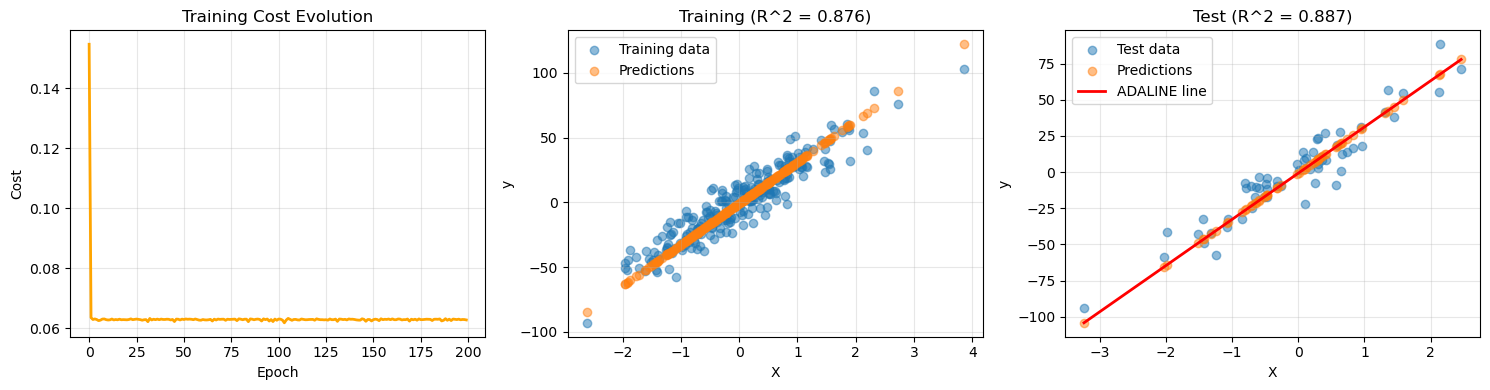

In [23]:
class AdalineRegressor(Adaline):
    #ADALINE adapted for regression (no sign function)
    def predict(self, X):
        # regression output --> continuous
        return self.net_input(X)
    def score(self, X,y):
        # R^2 score for regression
        y_pred = self.predict(X)
        ss_res = np.sum((y - y_pred) ** 2)
        ss_tot = np.sum((y - np.mean(y)) **2)
        return 1 - (ss_res / ss_tot) if ss_tot != 0 else 0
# Geenerate regression data
X_reg, y_reg = make_regression(n_samples = 300, n_features =1, noise = 10, random_state=42)
y_reg = y_reg.astype(float)
#Split
X_train, X_test, y_train, y_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state= 42)
#Standardize
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1,1)).ravel()
y_test_scaled = scaler_y.fit_transform(y_test.reshape(-1,1)).ravel()

#Train ADALINE regressor
a_reg =AdalineRegressor(learning_rate = 0.01, n_epochs = 200, random_state=42)
a_reg.fit(X_train_scaled, y_train_scaled, verbose=False)

# Predict and inverse transform
y_train_pred_scaled = a_reg.predict(X_train_scaled)
y_test_pred_scaled = a_reg.predict(X_test_scaled)

y_train_pred = scaler_y.inverse_transform(y_train_pred_scaled.reshape(-1,1)).ravel()
y_test_pred=  scaler_y.inverse_transform(y_test_pred_scaled.reshape(-1,1)).ravel()

#Calculate R^2 scores
train_r2 = a_reg.score(X_train_scaled, y_train_scaled)
test_r2 = a_reg.score(X_test_scaled, y_test_scaled)
train_mse = mean_squared_error(y_train,y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

print("\n" + "="*60)
print("ADALINE for Regression")
print("="*60)
print(f"Training R^2: {train_r2:.4f}")
print(f"Test R^2: {test_r2:.4f}")
print(f"Training MSE: {train_mse:.4f}")
print(f"Test MSE: {test_mse:.4f}")
print(f"Weights: {a_reg.weights}")
print(f"Bias: {a_reg.bias:.4f}")

#Plot results
plt.figure(figsize =(15,4))
plt.subplot(1,3,1)
plt.plot(a_reg.cost_history, linewidth = 2, color='orange')
plt.xlabel('Epoch')
plt.ylabel('Cost')
plt.title('Training Cost Evolution')
plt.grid(True, alpha = 0.3)

plt.subplot(1,3,2)
plt.scatter(X_train, y_train, alpha=0.5, label = 'Training data')
plt.scatter(X_train, y_train_pred, alpha = 0.5, label='Predictions')

plt.xlabel('X')
plt.ylabel('y')
plt.title(f"Training (R^2 = {train_r2:.3f})")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1,3,3)
plt.scatter(X_test, y_test, alpha= 0.5, label='Test data')
plt.scatter(X_test, y_test_pred,alpha=0.5, label='Predictions')
#Plot regression line
X_line = np.linspace(X_test.min(), X_test.max(), 100).reshape(-1,1)
X_line_scaled = scaler_X.transform(X_line)
y_line_scaled = a_reg.predict(X_line_scaled)
y_line= scaler_y.inverse_transform(y_line_scaled.reshape(-1,1)).ravel()
plt.plot(X_line, y_line, 'r-', linewidth = 2, label ='ADALINE line')
plt.xlabel('X')
plt.ylabel('y')
plt.title(f'Test (R^2 = {test_r2:.3f})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



        

## ADALINE on Iris Dataset

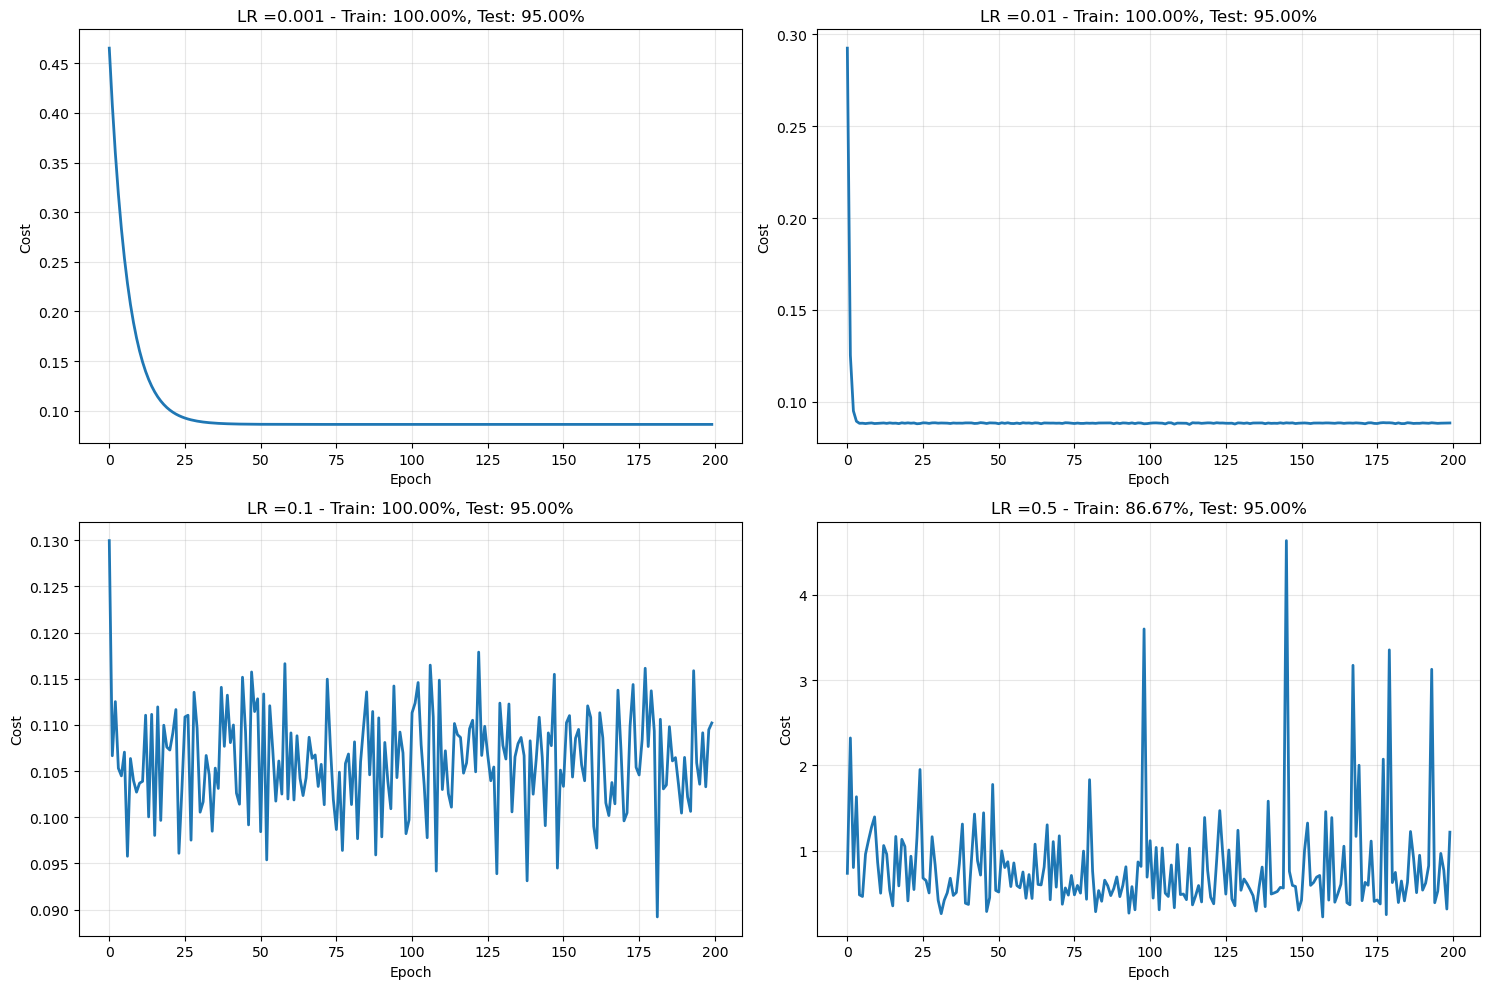


ADALINE on Iris Dataset
Best learning rate : 0.001
Best test accuracy: 95.00%
Final weights: [ 0.63817114 -0.54884074]
Final bias: 0.0573
Final cost: 0.086299


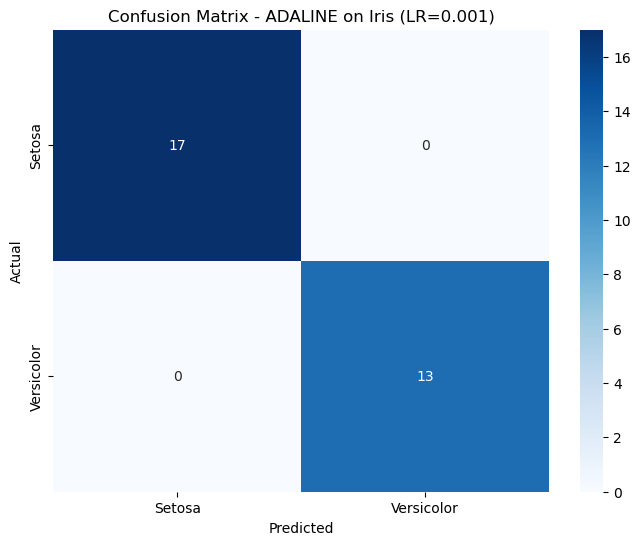

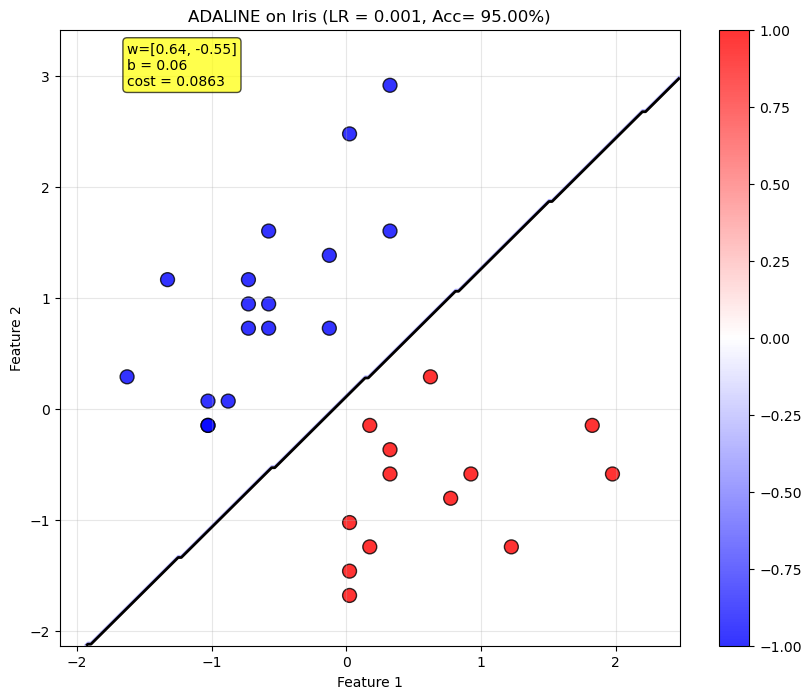

In [28]:
from sklearn.datasets import load_iris
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

#Load Iris datsets (2 classes only(
iris  = load_iris()
X_iris = iris.data[:100, :2] # First 2 classes. first 2 features
y_iris = iris.target[:100]
y_iris  = np.where(y_iris == 0, -1, 1) # Convert to -1/1
#split
X_train, X_test, y_train,y_test = train_test_split(X_iris, y_iris, test_size = 0.3, random_state = 42)

#Standardize 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#Train ADALINE with different learning rates
learning_rates = [0.001, 0.01, 0.1, 0.5]
best_acc = 0
best_lr = None
best_a = None
plt.figure(figsize=(15,10))
for i, lr in enumerate(learning_rates):
    a = Adaline(learning_rate = lr, n_epochs = 200, random_state = 42)
    a.fit(X_train_scaled, y_train, verbose = False)
    train_acc = a.score(X_test_scaled, y_test)

    plt.subplot(2,2, i+1)
    plt.plot(a.cost_history, linewidth=2)
    plt.xlabel('Epoch')
    plt.ylabel('Cost')
    plt.title(f'LR ={lr} - Train: {train_acc:.2%}, Test: {test_acc:.2%}')
    plt.grid(True, alpha=0.3)
    if test_acc > best_acc:
        best_acc = test_acc
        best_lr = lr
        best_a = a
plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("ADALINE on Iris Dataset")
print("=" *60)
print(f"Best learning rate : {best_lr}")
print(f"Best test accuracy: {best_acc:.2%}")
print(f"Final weights: {best_a.weights}")
print(f"Final bias: {best_a.bias:.4f}")
print(f"Final cost: {best_a.cost_history[-1]:.6f}")

#confusion matrix
test_pred = best_a.predict(X_test_scaled)
cm = confusion_matrix(y_test,test_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Setosa', 'Versicolor'],
            yticklabels=['Setosa', 'Versicolor'])
plt.title(f'Confusion Matrix - ADALINE on Iris (LR={best_lr})')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

#Decision boundary visualization function
def plot_adaline_decision_boundary(adaline, X, y, scaler = None, title="ADALINE Decision Boundary"):
    #Plot decision boundary for ADALINE
    if scaler:
        X_plot = X
    else:
        X_plot= X
    #Create mesh grid
    x_min, x_max = X_plot[:, 0].min() - 0.5, X_plot[:, 0].max() + 0.5
    y_min, y_max = X_plot[:, 0].min() - 0.5, X_plot[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200))

    #Predict on grid
    Z = adaline.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    #Plot
    plt.figure(figsize=(10, 8))
    plt.contour(xx, yy, Z, alpha=0.3, levels=[-1, 0, 1], colors=['blue', 'red'])
    plt.contour(xx, yy, Z, levels=[0], colors='black', linewidths = 2)

    #Plot data points
    scatter = plt.scatter(X_plot[:, 0], X_plot[:, 1], c=y, cmap='bwr', edgecolors='black', s=100, alpha=0.8)

    #Add weights and bias info
    w = adaline.weights
    b = adaline.bias
    plt.text(x_min + 0.5, y_max - 0.5, f'w=[{w[0]:.2f}, {w[1]:.2f}]\nb = {b:.2f}\ncost = { adaline.cost_history[-1]:.4f}', bbox=dict(boxstyle="round,pad=0.3", facecolor="yellow", alpha=0.7))
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.title(title)
    plt.colorbar(scatter)
    plt.grid(True, alpha=0.3)
    plt.show()
plot_adaline_decision_boundary(best_a, X_test_scaled, y_test, scaler, f"ADALINE on Iris (LR = {best_lr}, Acc= {best_acc:.2%})")

## Learning with Momentum


ADALINE with VS without Momentum


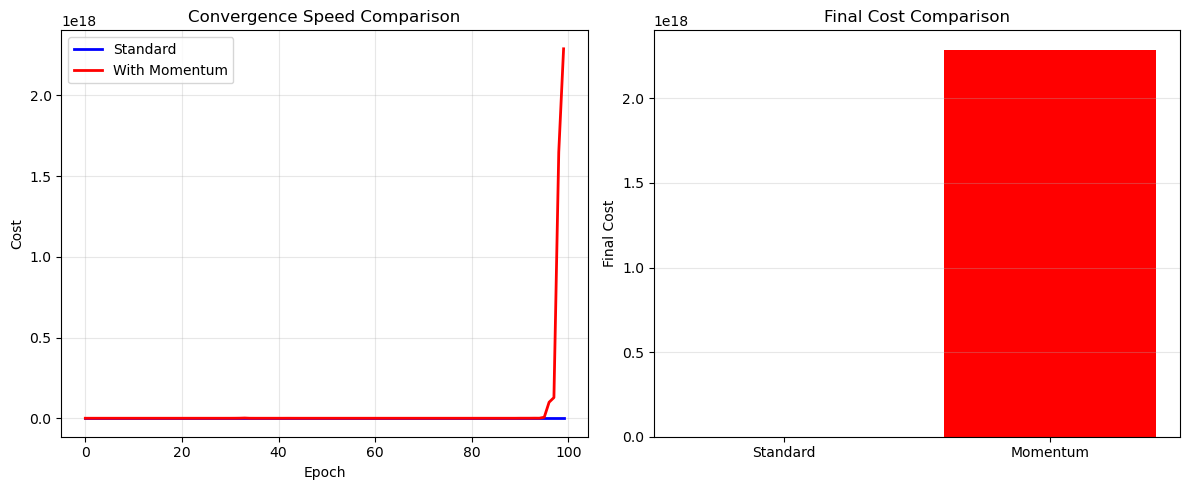

Standard ADALINE - Final cost: 0.099718
Momentum ADALINE - Final cost: 2287962262927492352.000000
Improvement: -2294429327723944738816.00%


In [32]:
class AdalineMomentum(Adaline):
    #ADALINE with momentum for faster convergence
    def __init__(self, learning_rate = 0.01, n_epochs = 50, momentum = 0.9, random_state=None):
        super().__init__(learning_rate, n_epochs, random_state=random_state)
        self.momentum= momentum
        self.weight_update = None
        self.bias_update = None
    def fit(self, X, y, verbose = True):
        n_samples, n_features = X.shape
        self._initialize_weights(n_features)
        self.cost_history=[]
        self.weights_history = [self.weights.copy()]
        # Initialize momentum terms
        self.weight_update = np.zeros(n_features)
        self.bias_update = 0.0
        for epoch in range(self.n_epochs):
            # Shuffle data 
            indices = np.random.permutation(n_samples)
            X_shuffled = X[indices]
            y_shuffled = y[indices]

            epoch_cost = 0
            for xi, target in zip(X_shuffled, y_shuffled):
                #Compute output
                output = self.activation(xi.reshape(1,-1))[0]

                #Compute error
                error = target - output

                #Compute gradient
                weight_grad = error * xi
                bias_grad = error

                #Update with momentum
                self.weight_update = self.momentum *self.weight_update + self.lr * weight_grad
                self.bias_update = self.momentum * self.bias_update + self.lr *bias_grad
                self.weights += self.weight_update
                self.bias += self.bias_update
                epoch_cost += error**2
            epoch_cost /= (2 * n_samples)
            self.cost_history.append(epoch_cost)
            self.weights_history.append(self.weights.copy())

            if verbose and (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1} / {self.n_epochs}, Cost: {epoch_cost:.6f}")
        return self
#Compare with and without momentum
print("\n" + "=" *60)
print("ADALINE with VS without Momentum")
print("="*60)

a_standard = Adaline(learning_rate=0.1, n_epochs = 100, random_state = 42)
a_momentum = AdalineMomentum(learning_rate = 0.1, n_epochs = 100, momentum= 0.9, random_state= 42)
a_standard.fit(X_train_scaled, y_train, verbose=False)
a_momentum.fit(X_train_scaled, y_train, verbose=False)

#Plot comparison
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(a_standard.cost_history, linewidth = 2, label='Standard', color='blue')
plt.plot(a_momentum.cost_history, linewidth = 2, label='With Momentum', color='red')
plt.xlabel('Epoch')
plt.ylabel('Cost')
plt.title('Convergence Speed Comparison')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1,2,2)
#This is a simplified visualization
plt.bar(['Standard', 'Momentum'],[a_standard.cost_history[-1], a_momentum.cost_history[-1]], color=['blue', 'red'])
plt.ylabel('Final Cost')
plt.title('Final Cost Comparison')
plt.grid(True, alpha=0.3, axis ='y')
plt.tight_layout()
plt.show()

print(f"Standard ADALINE - Final cost: {a_standard.cost_history[-1]:.6f}")
print(f"Momentum ADALINE - Final cost: {a_momentum.cost_history[-1]:.6f}")
print(f"Improvement: {(a_standard.cost_history[-1] - a_momentum.cost_history[-1]) / a_standard.cost_history[-1] * 100:.2f}%")

## Learning Rate Decay


ADALINE with learning rate decay


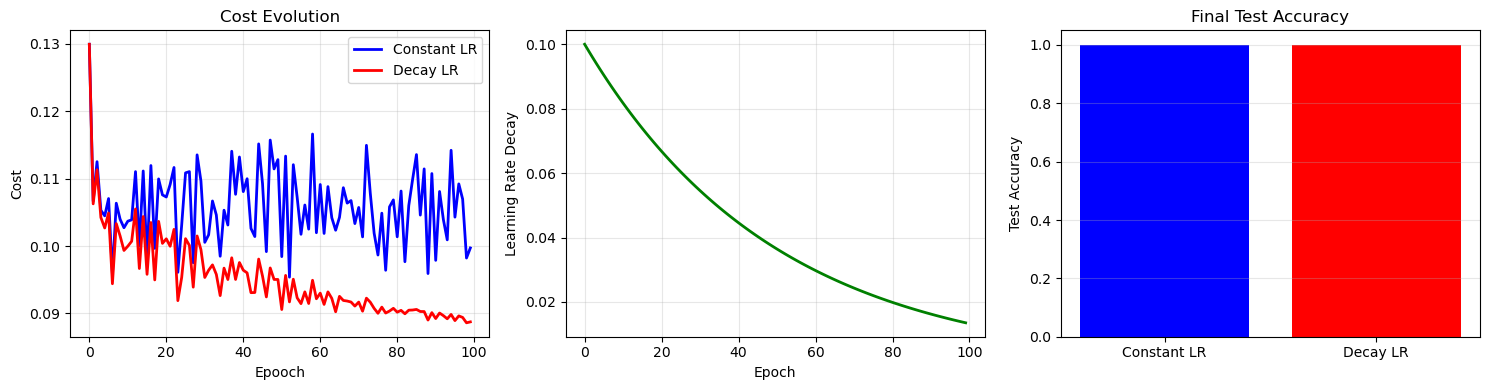

constant LR - Final cost: 0.099718, Test acc: 100.00%
Decay LR - Final cost: 0.088743, Test acc: 100.00%


In [43]:
class AdalineDecay(Adaline):
    # ADALINE with learning rate decay
    def __init__(self, learning_rate = 0.1, n_epochs= 50, decay_rate = 0.99, random_state=None):
        super().__init__(learning_rate, n_epochs, random_state=random_state)
        self.decay_rate = decay_rate
        self.learning_rates =[]
    def fit(self, X, y, verbose= True):
        n_samples, n_features = X.shape
        self._initialize_weights(n_features)
        self.cost_history = []
        self.weights_history  =[self.weights.copy()]
        self.learning_rates = []

        current_lr = self.lr
        for epoch in range(self.n_epochs):
            #Shuffle data
            indices = np.random.permutation(n_samples)
            X_shuffled = X[indices]
            y_shuffled = y[indices]
            epoch_cost = 0

            for xi, target in zip(X_shuffled, y_shuffled):
                #Compute output
                output = self.activation(xi.reshape(1, -1))[0]
                #Compute error 
                error = target - output
                #Update with current learning rate
                self.weights += current_lr * error * xi
                self.bias  += current_lr * error
                epoch_cost += error**2
            epoch_cost /= (2 *n_samples)
            self.cost_history.append(epoch_cost)
            self.weights_history.append(self.weights.copy())
            self.learning_rates.append(current_lr)

            #Decay learning rate
            current_lr *= self.decay_rate
            if verbose and (epoch + 1) % 10 ++ 0:
                print(f"Epoch {epoch+1} /{self.n_epochs}, Cost: {epoch_cost:.6f}, LR: {current_lr:.6f}")
        return self
#Compare constant vs decay
print("\n" + "="*60)
print("ADALINE with learning rate decay")
print("="*60)

a_constant = Adaline(learning_rate = 0.1, n_epochs = 100, random_state=42)
a_decay = AdalineDecay(learning_rate = 0.1, n_epochs=100, decay_rate =0.98, random_state=42)

a_constant.fit(X_train_scaled, y_train, verbose=False)
a_decay.fit(X_train_scaled, y_train, verbose=False)

#Plot comparison
plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
plt.plot(a_constant.cost_history,linewidth=2, label='Constant LR', color='blue')
plt.plot(a_decay.cost_history, linewidth =2, label='Decay LR', color='red')
plt.xlabel('Epooch')
plt.ylabel('Cost')
plt.title('Cost Evolution')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1,3,2)
plt.plot(a_decay.learning_rates, linewidth =2, color='green')
plt.xlabel('Epoch')
plt.ylabel('Learning Rate Decay')
plt.grid(True, alpha =0.3)

plt.subplot(1,3,3)
#Final test accuracy
test_acc_const= a_constant.score(X_test_scaled, y_test)
test_acc_decay = a_decay.score(X_test_scaled, y_test)
plt.bar(['Constant LR', 'Decay LR'], [test_acc_const, test_acc_decay], color=['blue', 'red'])
plt.ylabel('Test Accuracy')
plt.title('Final Test Accuracy')
plt.grid(True, alpha=0.3, axis ='y')

plt.tight_layout()
plt.show()
print(f"constant LR - Final cost: {a_constant.cost_history[-1]:.6f}, Test acc: {test_acc_const:.2%}")
print(f"Decay LR - Final cost: {a_decay.cost_history[-1]:.6f}, Test acc: {test_acc_decay:.2%}")